<a href="https://colab.research.google.com/github/donjperpetua/ML_ENG_HW1/blob/main/ML_ENG_HW5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Donald Perpetua | RIN: 662040925

In [2]:
# Question 1
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

#CNN
model = models.Sequential([
    layers.Input(shape=(32, 32, 3)),

    #first convolutional layer
    layers.Conv2D(64, (5, 5), activation='relu'),

    #second layer: max pooling
    layers.MaxPooling2D(pool_size=(2, 2)),

    #third convolutional layer
    layers.Conv2D(32, (3, 3), activation='relu'),

    #fourth layer: max pooling
    layers.MaxPooling2D(pool_size=(2, 2)),

    #fifth convolutional layer
    layers.Conv2D(32, (3, 3), activation='relu'),

    #sixth layer: flatten
    layers.Flatten(),

    #seventh layer: dense
    layers.Dense(64, activation='relu'),

    #eighth layer: output probabilities for 10 classes
    layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 32)       │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 66,058 (258.04 KB)

 Trainable params: 66,058 (258.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 95s 120ms/step - accuracy: 0.7172 - loss: 0.8058 - val_accuracy: 0.6704 - val_loss: 0.9694
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 92s 117ms/step - accuracy: 0.7258 - loss: 0.7801 - val_accuracy: 0.6795 - val_loss: 0.9319
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 143s 119ms/step - accuracy: 0.7359 - loss: 0.7524 - val_accuracy: 0.6815 - val_loss: 0.9342
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 93s 119ms/step - accuracy: 0.7418 - loss: 0.7308 - val_accuracy: 0.6858 - val_loss: 0.9454
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 91s 117ms/step - accuracy: 0.7520 - loss: 0.7102 - val_accuracy: 0.6803 - val_loss: 0.9770
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 93s 119ms/step - accuracy: 0.7565 - loss: 0.6923 - val_accuracy: 0.6935 - val_loss: 0.9167
Epoch 7/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 92s 118ms/step - accuracy: 0.7623 - loss: 0.6756 - val_accuracy: 0.6818 - val_loss: 0.9556
Epoch 8/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 92s 118ms/step - accuracy: 0.7705 - loss: 

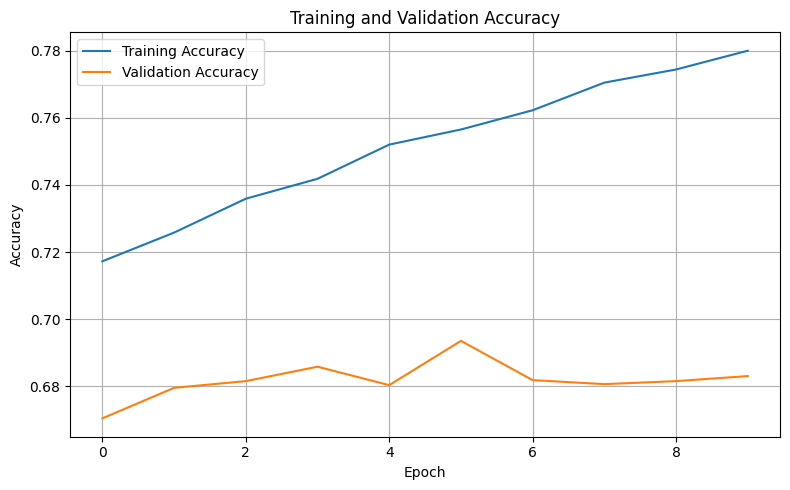

In [4]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_test, y_test)
)

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Question 2

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

data = load_breast_cancer(as_frame=True)
df = data.frame

X = df[[
    'worst compactness',
    'worst concavity',
    'worst area'
]]

#Target: malignant or benign
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

#SVM with a linear kernel
svm_linear = SVC(kernel='linear')
svm_linear.fit(X_train_scaled, y_train)

y_pred_linear = svm_linear.predict(X_test_scaled)
accuracy_linear = accuracy_score(y_test, y_pred_linear)

print(f'Linear kernel accuracy: {accuracy_linear:.4f}')
print(f'Linear kernel accuracy: {accuracy_linear:.2%}')

#SVM with an RBF kernel and C=2
svm_rbf = SVC(kernel='rbf', C=2)
svm_rbf.fit(X_train_scaled, y_train)

y_pred_rbf = svm_rbf.predict(X_test_scaled)
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)

print(f'RBF kernel accuracy (C=2): {accuracy_rbf:.4f}')
print(f'RBF kernel accuracy (C=2): {accuracy_rbf:.2%}')

Linear kernel accuracy: 0.9386
Linear kernel accuracy: 93.86%
RBF kernel accuracy (C=2): 0.9474
RBF kernel accuracy (C=2): 94.74%
